In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_PATH = Path("../data/raw/ai4i2020.csv")

df = pd.read_csv(DATA_PATH)

TARGET = "Machine failure"

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training failure rate:", f"{y_train.mean():.2%}")
print("Testing failure rate:", f"{y_test.mean():.2%}")

Training rows: 8000
Testing rows: 2000
Training failure rate: 3.39%
Testing failure rate: 3.40%


Build the complete preprocessing pipeline

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

In [5]:
models = {
    "Dummy": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOM_STATE,
    ),
}

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model)),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )

    results.append({
        "Model": name,
        "Average Precision": scores["test_average_precision"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("Average Precision", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))

/Users/user/Projects/MachineGuard/ml/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/user/Projects/MachineGuard/ml/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/user/Projects/MachineGuard/ml/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

,Model,Average Precision,Precision,Recall,F1
0,Random Forest,0.7298,0.5999,0.7416,0.6622
1,Gradient Boosting,0.6751,0.8012,0.3432,0.4795
2,Logistic Regression,0.4409,0.1374,0.8044,0.2346
3,Dummy,0.0339,0.0000,0.0000,0.0000


In [7]:
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
)

best_model_name = "Random Forest"

best_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models[best_model_name])),
])

best_pipeline.fit(X_train, y_train)

# Probability that each machine belongs to the failure class
y_test_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Default threshold
y_test_pred = (y_test_proba >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0,
))

print("Average Precision:",
      round(average_precision_score(y_test, y_test_proba), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_test_proba), 4))

              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99      1932
     Failure       0.59      0.78      0.67        68

    accuracy                           0.97      2000
   macro avg       0.79      0.88      0.83      2000
weighted avg       0.98      0.97      0.98      2000

Average Precision: 0.751
ROC-AUC: 0.967


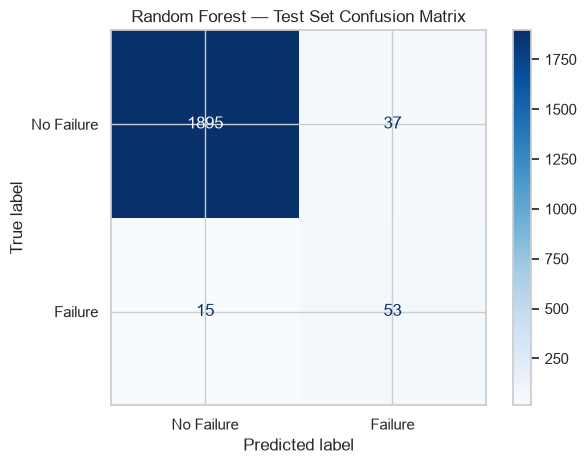

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Blues",
    values_format="d",
)

plt.title("Random Forest — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

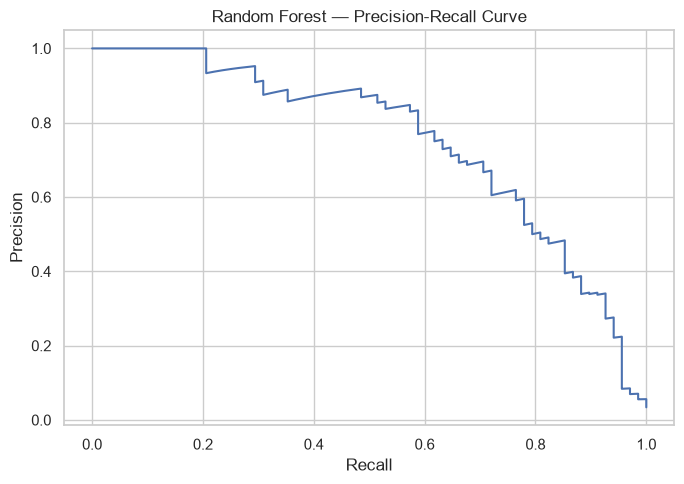

In [9]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_proba,
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest — Precision-Recall Curve")
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models["Random Forest"])),
])

# Out-of-fold probabilities: each training observation is scored
# by a model that did not train on that observation.
oof_proba = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds_to_test = np.arange(0.10, 0.71, 0.05)

threshold_results = []

for threshold in thresholds_to_test:
    predictions = (oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "F2": fbeta_score(
            y_train, predictions, beta=2, zero_division=0
        ),
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,Precision,Recall,F1,F2
0,0.10,0.224,0.956,0.362,0.578
1,0.15,0.269,0.945,0.418,0.628
2,0.20,0.306,0.908,0.458,0.652
3,0.25,0.347,0.897,0.501,0.681
4,0.30,0.388,0.882,0.539,0.703
5,0.35,0.441,0.834,0.577,0.708
6,0.40,0.498,0.823,0.620,0.728
7,0.45,0.540,0.790,0.642,0.723
8,0.50,0.598,0.742,0.662,0.708
9,0.55,0.642,0.694,0.667,0.683


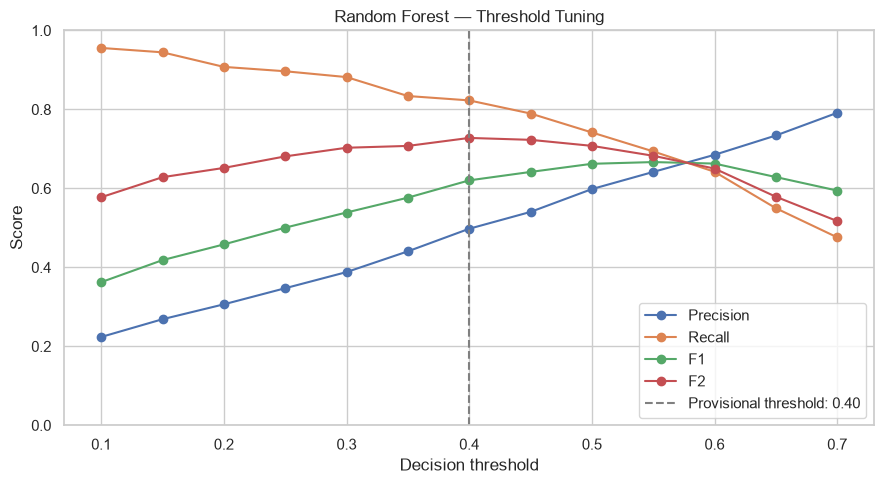

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision",
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall",
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1",
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["F2"],
    marker="o",
    label="F2",
)

ax.axvline(
    0.40,
    linestyle="--",
    color="gray",
    label="Provisional threshold: 0.40",
)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Random Forest — Threshold Tuning")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

for threshold in [0.40, 0.50]:
    test_predictions = (
        y_test_proba >= threshold
    ).astype(int)

    print(f"\n{'=' * 45}")
    print(f"Threshold: {threshold:.2f}")
    print("=" * 45)

    print(classification_report(
        y_test,
        test_predictions,
        target_names=["No Failure", "Failure"],
        zero_division=0,
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test, test_predictions))


Threshold: 0.40
              precision    recall  f1-score   support

  No Failure       0.99      0.97      0.98      1932
     Failure       0.47      0.82      0.60        68

    accuracy                           0.96      2000
   macro avg       0.73      0.90      0.79      2000
weighted avg       0.98      0.96      0.97      2000

Confusion matrix:
[[1870   62]
 [  12   56]]

Threshold: 0.50
              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99      1932
     Failure       0.59      0.78      0.67        68

    accuracy                           0.97      2000
   macro avg       0.79      0.88      0.83      2000
weighted avg       0.98      0.97      0.98      2000

Confusion matrix:
[[1895   37]
 [  15   53]]


Save Final Model

In [14]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from pathlib import Path
import joblib
import json

# Keep this threshold fixed for the current version
DECISION_THRESHOLD = 0.40

# Create a fresh pipeline
final_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models["Random Forest"])),
])

# Train using only the training data
final_pipeline.fit(X_train, y_train)

print("Final Random Forest pipeline trained.")

Final Random Forest pipeline trained.


In [15]:
ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "model.joblib"

joblib.dump(final_pipeline, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH.resolve()}")

Model saved to: /Users/user/Projects/MachineGuard/ml/artifacts/model.joblib


In [16]:
#saving meta data
metadata = {
    "model_name": "Random Forest",
    "model_version": "1.0.0",
    "decision_threshold": DECISION_THRESHOLD,
    "target": TARGET,
    "positive_class": 1,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "dataset": "AI4I 2020 Predictive Maintenance Dataset",
    "threshold_status": "provisional",
}

METADATA_PATH = ARTIFACT_DIR / "metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print(f"Metadata saved to: {METADATA_PATH.resolve()}")

Metadata saved to: /Users/user/Projects/MachineGuard/ml/artifacts/metadata.json


In [17]:
loaded_pipeline = joblib.load(MODEL_PATH)

# Use the same test records as before
original_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
loaded_probabilities = loaded_pipeline.predict_proba(X_test)[:, 1]

assert np.allclose(
    original_probabilities,
    loaded_probabilities,
), "Reloaded model predictions do not match!"

loaded_predictions = (
    loaded_probabilities >= DECISION_THRESHOLD
).astype(int)

print("Model reload verification passed.")
print("Decision threshold:", DECISION_THRESHOLD)
print("Test records evaluated:", len(X_test))
print("Predicted failure cases:", int(loaded_predictions.sum()))

Model reload verification passed.
Decision threshold: 0.4
Test records evaluated: 2000
Predicted failure cases: 118


In [18]:
sample_machine = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 120,
}])

failure_probability = loaded_pipeline.predict_proba(
    sample_machine
)[0, 1]

prediction = int(
    failure_probability >= DECISION_THRESHOLD
)

print(f"Failure probability score: {failure_probability:.2%}")
print(f"Decision threshold: {DECISION_THRESHOLD:.2f}")
print(f"Predicted class: {prediction}")
print(
    "Prediction:",
    "Failure risk flagged" if prediction == 1
    else "Failure risk not flagged"
)

Failure probability score: 0.00%
Decision threshold: 0.40
Predicted class: 0
Prediction: Failure risk not flagged
